<a href="https://colab.research.google.com/github/Camminh-programmer/MachineLearning_HUIT/blob/main/52_HaCamMinh_2001240273.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**BÀI TẬP Ở LỚP**

**BÀI 1**

**1. Cần xây dựng một mô hình hồi quy tuyến tính đơn giản để dự đoán giá bán dựa trên diện tích nhà**

Hệ số góc: 15.20
Hệ số chặn: 85.11
MSE: 4444.72
R^2 Score: 0.97


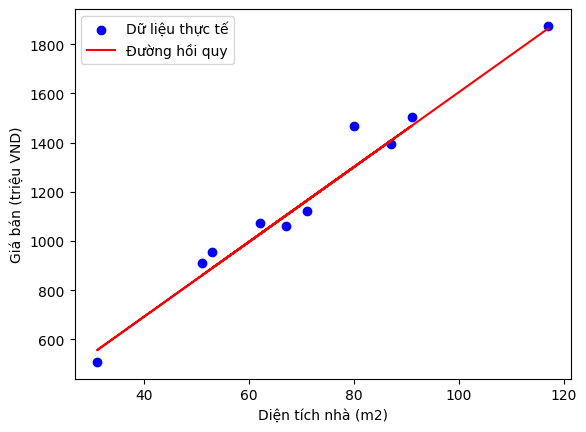

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
X = np.random.randint(30, 150, 50).reshape(-1, 1)
y = 15 * X + 100 + np.random.randn(50, 1) * 50

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model_simple = LinearRegression()
model_simple.fit(X_train, y_train)
y_pred = model_simple.predict(X_test)

print(f"Hệ số góc: {model_simple.coef_[0][0]:.2f}")
print(f"Hệ số chặn: {model_simple.intercept_[0]:.2f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2 Score: {r2_score(y_test, y_pred):.2f}")

plt.scatter(X_test, y_test, color='blue', label='Dữ liệu thực tế')
plt.plot(X_test, y_pred, color='red', label='Đường hồi quy')
plt.xlabel('Diện tích nhà (m2)')
plt.ylabel('Giá bán (triệu VND)')
plt.legend()
plt.show()

**2. Thêm nhiều (số lượng) dữ liệu và độ nhiễu để xem mô hình hoạt động như thế nào**

MSE (nhiều nhiễu): 107644.01
R^2 Score (nhiều nhiễu): 0.69


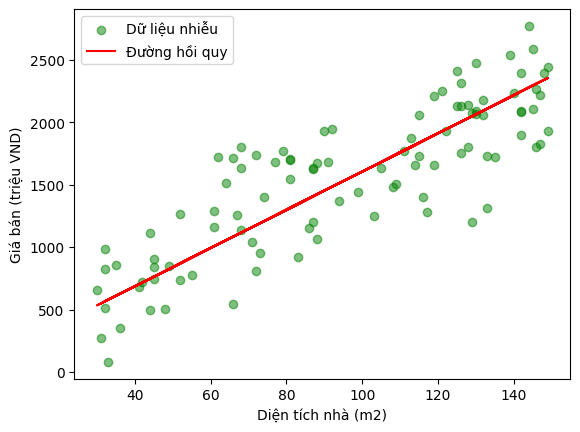

In [2]:
X_large = np.random.randint(30, 150, 500).reshape(-1, 1)
y_noisy = 15 * X_large + 100 + np.random.randn(500, 1) * 300

X_train_n, X_test_n, y_train_n, y_test_n = train_test_split(X_large, y_noisy, test_size=0.2, random_state=42)

model_noisy = LinearRegression()
model_noisy.fit(X_train_n, y_train_n)
y_pred_n = model_noisy.predict(X_test_n)

print(f"MSE (nhiều nhiễu): {mean_squared_error(y_test_n, y_pred_n):.2f}")
print(f"R^2 Score (nhiều nhiễu): {r2_score(y_test_n, y_pred_n):.2f}")

plt.scatter(X_test_n, y_test_n, color='green', alpha=0.5, label='Dữ liệu nhiễu')
plt.plot(X_test_n, y_pred_n, color='red', label='Đường hồi quy')
plt.xlabel('Diện tích nhà (m2)')
plt.ylabel('Giá bán (triệu VND)')
plt.legend()
plt.show()

**3. Thêm các biến đầu vào khác để nâng cao tính phức tạp của mô hình**

In [3]:
X_multi = np.c_[
    np.random.randint(30, 150, 500),
    np.random.randint(1, 5, 500),
    np.random.randint(1, 20, 500)
]

y_multi = (15 * X_multi[:, 0] + 50 * X_multi[:, 1] - 10 * X_multi[:, 2]).reshape(-1, 1) + 100 + np.random.randn(500, 1) * 100

X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X_multi, y_multi, test_size=0.2, random_state=42)

model_multi = LinearRegression()
model_multi.fit(X_train_m, y_train_m)
y_pred_m = model_multi.predict(X_test_m)

print(f"Hệ số góc (Diện tích, Phòng ngủ, Tuổi): {model_multi.coef_[0]}")
print(f"Hệ số chặn: {model_multi.intercept_[0]:.2f}")
print(f"MSE (Đa biến): {mean_squared_error(y_test_m, y_pred_m):.2f}")
print(f"R^2 Score (Đa biến): {r2_score(y_test_m, y_pred_m):.2f}")

Hệ số góc (Diện tích, Phòng ngủ, Tuổi): [15.07138953 51.97006692 -9.43125835]
Hệ số chặn: 88.95
MSE (Đa biến): 8589.78
R^2 Score (Đa biến): 0.97


**BÀI 2**

**1. Tạo dữ liệu mẫu giả lập với đặc trưng BMI và nhãn mắc bệnh dựa trên mối liên hệ logic (BMI cao có thể dẫn đến khả năng mắc bệnh cao hơn)**

In [7]:
import numpy as np

np.random.seed(42)

BMI = np.random.uniform(15,40,200).reshape(-1,1)

probabilities = 1 / (1 + np.exp(-(0.5 * BMI - 12.5)))

y = (np.random.rand(200, 1) < probabilities).astype(int).ravel()

**2. Sử dụng thư viện phù hợp (HD: scikit-learn) để xây dựng một mô hình hồi quy logistic.**

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

model = LogisticRegression()

**3. Huấn luyện mô hình trên tập dữ liệu mẫu**

In [9]:
X_train, X_test, y_train, y_test = train_test_split(BMI, y, test_size=0.2, random_state=42)

model.fit(X_train, y_train)

LogisticRegression()

**4. Dự đoán xác suất và nhãn mắc bệnh cho một tập dữ liệu kiểm tra**

In [10]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

print("Nhãn dự đoán:", y_pred[:5])
print("Xác suất dự đoán:", y_prob[:5])

Nhãn dự đoán: [1 0 1 0 0]
Xác suất dự đoán: [0.84355588 0.0509223  0.96689483 0.10719795 0.00388799]


**5. Đánh giá hiệu quả của mô hình thông qua độ chính xác và ma trận nhầm lẫn**

In [11]:
from sklearn.metrics import accuracy_score, confusion_matrix

print(f"Độ chính xác (Accuracy): {accuracy_score(y_test, y_pred):.2f}")
print("Ma trận nhầm lẫn (Confusion Matrix):")
print(confusion_matrix(y_test, y_pred))

Độ chính xác (Accuracy): 0.88
Ma trận nhầm lẫn (Confusion Matrix):
[[14  3]
 [ 2 21]]


**6. Trực quan hóa dữ liệu và đường hồi quy logistic**

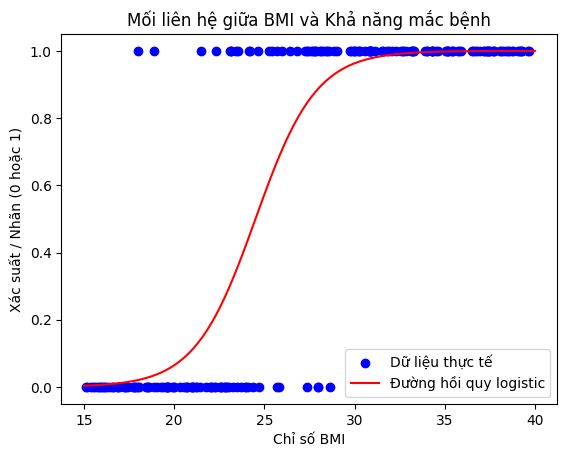

In [12]:
import matplotlib.pyplot as plt

X_range = np.linspace(15, 40, 100).reshape(-1, 1)
y_prob_range = model.predict_proba(X_range)[:, 1]

plt.scatter(BMI, y, color='blue', label='Dữ liệu thực tế')
plt.plot(X_range, y_prob_range, color='red', label='Đường hồi quy logistic')

plt.title('Mối liên hệ giữa BMI và Khả năng mắc bệnh')
plt.xlabel('Chỉ số BMI')
plt.ylabel('Xác suất / Nhãn (0 hoặc 1)')
plt.legend()
plt.show()

**BÀI 3**

--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---
Hệ số góc (TV, Radio, Newspaper): [0.04472952 0.18919505 0.00276111]
Hệ số chặn (Intercept): 2.98
Mean Squared Error (MSE): 3.17
R^2 Score: 0.90


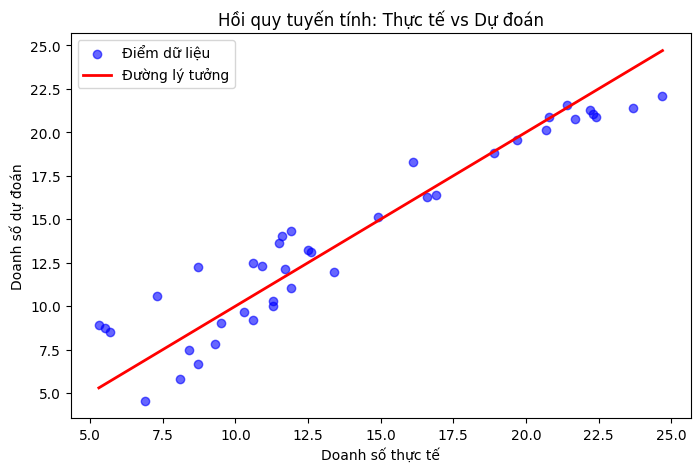

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

url = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
data = pd.read_csv(url, index_col=0)

X = data[['TV', 'Radio', 'Newspaper']]
y = data['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("--- KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ---")
print(f"Hệ số góc (TV, Radio, Newspaper): {model.coef_}")
print(f"Hệ số chặn (Intercept): {model.intercept_:.2f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.2f}")
print(f"R^2 Score: {r2_score(y_test, y_pred):.2f}")

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, label='Điểm dữ liệu')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', lw=2, label='Đường lý tưởng')
plt.xlabel('Doanh số thực tế')
plt.ylabel('Doanh số dự đoán')
plt.title('Hồi quy tuyến tính: Thực tế vs Dự đoán')
plt.legend()
plt.show()

**BÀI TẬP VỀ NHÀ**

**BÀI 1: Thay đổi điều kiện sinh dữ liệu, ví dụ tăng độ nhiễu để kiểm tra độ chính xác của mô hình**

In [14]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

np.random.seed(42)
X = 2 * np.random.rand(100, 1)

y_high_noise = 4 + 3 * X + np.random.randn(100,1) * 5

X_train, X_test, y_train, y_test = train_test_split(X, y_high_noise, test_size=0.2, random_state=42)

model_noise = LinearRegression()
model_noise.fit(X_train, y_train)
y_pred_noise = model_noise.predict(X_test)

print("--- BÀI 1: TĂNG ĐỘ NHIỄU ---")
print(f"MSE (Nhiễu cao): {mean_squared_error(y_test, y_pred_noise):.2f}")
print(f"R^2 Score (Nhiễu cao): {r2_score(y_test, y_pred_noise):.2f}")

--- BÀI 1: TĂNG ĐỘ NHIỄU ---
MSE (Nhiễu cao): 16.34
R^2 Score (Nhiễu cao): -0.05


 **Bài 2. Đổi ngưỡng dự đoán xác suất (ví dụ 0.6, 0.7,... thay vì 0.5) và quan sát sự thay đổi
trong kết quả dự đoán.**

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

np.random.seed(42)
BMI = np.random.uniform(15, 40, 200).reshape(-1, 1)
probabilities = 1 / (1 + np.exp(-(0.5 * BMI - 12.5)))
y = (np.random.rand(200, 1) < probabilities).astype(int).ravel()

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(BMI, y, test_size=0.2, random_state=42)
model_log = LogisticRegression()
model_log.fit(X_train_c, y_train_c)

y_prob = model_log.predict_proba(X_test_c)[:, 1]

print("\n--- BÀI 2: THAY ĐỔI NGƯỠNG DỰ ĐOÁN ---")
for threshold in [0.5, 0.6, 0.7]:
    y_pred_custom = (y_prob >= threshold).astype(int)
    acc = accuracy_score(y_test_c, y_pred_custom)
    print(f"Ngưỡng {threshold}: Độ chính xác = {acc:.3f}")


--- BÀI 2: THAY ĐỔI NGƯỠNG DỰ ĐOÁN ---
Ngưỡng 0.5: Độ chính xác = 0.875
Ngưỡng 0.6: Độ chính xác = 0.875
Ngưỡng 0.7: Độ chính xác = 0.925


**Bài 3. Hồi quy tuyến tính với tập dữ liệu giá nhà ở**

In [16]:
import pandas as pd

url = "https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv"
boston_df = pd.read_csv(url)

X_boston = boston_df.drop('medv', axis=1)
y_boston = boston_df['medv']

X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_boston, y_boston, test_size=0.2, random_state=42)

model_boston = LinearRegression()
model_boston.fit(X_train_b, y_train_b)

y_pred_b = model_boston.predict(X_test_b)

print("\n--- BÀI 3: BOSTON HOUSING ---")
print(f"MSE (Mean Squared Error): {mean_squared_error(y_test_b, y_pred_b):.2f}")
print(f"R^2 Score: {r2_score(y_test_b, y_pred_b):.2f}")


--- BÀI 3: BOSTON HOUSING ---
MSE (Mean Squared Error): 24.29
R^2 Score: 0.67
